In [1]:
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import pandas as pd
import numpy as np
import seaborn as sns
import scipy
import os
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib as mpl
plt.rcParams['figure.dpi'] = 500
import json
import sys
from matplotlib.pyplot import rc_context
pd.options.display.max_columns = None


In [2]:
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('retina')

In [3]:
sc.settings.figdir = 'figures/'

In [21]:
def leiden_resolution_plot(adata, resolutions=None, basis='umap'):
    
    for resolution in resolutions:
        leiden_key = f'leiden_{resolution:.2f}'  

        # Run Leiden clustering and store in adata.obs
        sc.tl.leiden(adata, resolution=resolution, key_added=leiden_key)

        # Plot UMAP with this clustering
        #sc.pl.umap(adata, color=leiden_key, legend_loc='on data', title=f'Leiden Clustering (Resolution {resolution:.2f})')

# leiden_resolution_plot(Treg, resolutions=[0.1, 0.15, 0.2])


In [22]:
# results_file = "gs://fc-e9295d8f-5730-4967-b1ce-22c3d775d7c2/CRC_Hubs_2021_dataset/crc_analysis_v2.h5ad" 

In [23]:
adata_treg = ad.read('crc_analysis_v2.h5ad')
foxp3cd8 = ad.read('foxp3cd8.h5ad')

/home/jupyter/.local/lib/python3.10/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/home/jupyter/.local/lib/python3.10/site-packages/anndata/__init__.py:55: FutureWarning: `anndata.read` is deprecated, use `anndata.read_h5ad` instead. `ad.read` will be removed in mid 2024.
  warnings.warn(
/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1818: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [24]:
adata_treg

AnnData object with n_obs × n_vars = 11755 × 3089
    obs: 'biosample_id', 'donor_id', 'SpecimenType', 'TissueSource', 'ProcessingMethod', 'PatientTypeID', 'sex', 'Site', 'Grade', 'TumorStage', 'LymphNodeStatus', 'MMRStatusTumor', 'MMRMLH1Tumor', 'qc_geneCount', 'qc_logMappedReads', 'qc_meanReadsPerUmi', 'qc_totalReads', 'qc_logUmiCount', 'qc_bcSwapFraction', 'qc_geneSatFraction', 'qc_seqDupEst', 'qc_umiSatFraction', 'qc_emptyDropPval', 'qc_mitoFraction', 'species', 'species__ontology_label', 'disease', 'disease__ontology_label', 'organ', 'organ__ontology_label', 'library_preparation_protocol', 'library_preparation_protocol__ontology_label', 'ClusterFull', 'ClusterMidway', 'leiden_0.20', 'leiden_0.25', 'leiden_0.30', 'leiden_0.40', 'leiden_0.50', 'leiden_0.65', 'leiden_subcluster'
    var: 'gene_ids', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection', 'mean', 'std'
    uns: 'ClusterFull_colors', 'dendrogram_leiden_

In [25]:
# subcluster the cluster 4 from resolution 0.5
sc.tl.leiden(adata_treg, restrict_to=('leiden_0.50', ['4']), key_added='leiden_subcluster_2', resolution = 0.10)

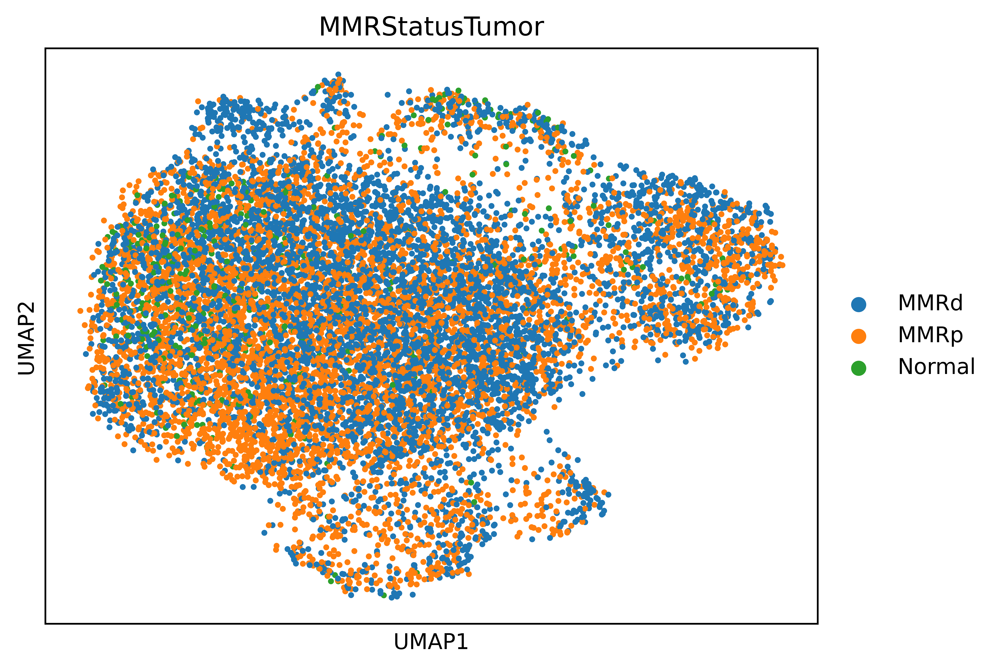

In [26]:
import matplotlib.pyplot as plt
import scanpy as sc

# Set the figure size before calling sc.pl.umap
# plt.figure(figsize=(20, 8))

# Plot UMAP with the specified color
sc.pl.umap(adata_treg, color=["MMRStatusTumor"], size=30)


In [27]:
# sc.pl.umap(adata_treg, color=["CD8A", "FOXP3", "CD8B", "CCL5", "GZMK"], ncols=3, color_map=mpl.cm.Reds) 

In [28]:
# sc.pl.umap(adata_treg, color=["ClusterFull"])

In [29]:
# sc.pl.umap(Treg, color=["FOXP3", "TCF7", "IL7R", "TNFRSF18", "TNFRSF4", "BATF", "IFNG", "CXCL13", "SELL", "CCR7"], ncols=3, color_map=mpl.cm.Reds) 

In [30]:
# sc.pl.umap(Treg, color=["CD8A", "FOXP3", "CD8B", "CCL5", "GZMK"], ncols=3, color_map=mpl.cm.Reds) 

In [31]:
# sc.pl.umap(Treg, color=["CD8A", "FOXP3", "CD8B", "CCL5", "GZMK"], ncols=2, color_map=mpl.cm.Reds) # cluster 6 CD8+ FOXP3+ Tregs

In [32]:
adata_treg.obs.head()

,biosample_id,donor_id,SpecimenType,TissueSource,ProcessingMethod,PatientTypeID,sex,Site,Grade,TumorStage,LymphNodeStatus,MMRStatusTumor,MMRMLH1Tumor,qc_geneCount,qc_logMappedReads,qc_meanReadsPerUmi,qc_totalReads,qc_logUmiCount,qc_bcSwapFraction,qc_geneSatFraction,qc_seqDupEst,qc_umiSatFraction,qc_emptyDropPval,qc_mitoFraction,species,species__ontology_label,disease,disease__ontology_label,organ,organ__ontology_label,library_preparation_protocol,library_preparation_protocol__ontology_label,ClusterFull,ClusterMidway,leiden_0.20,leiden_0.25,leiden_0.30,leiden_0.40,leiden_0.50,leiden_0.65,leiden_subcluster,leiden_subcluster_2
C103_T_1_1_0_c1_v2_id-AAAGTAGAGGACACCA,C103_T_1_1_0_c1_v2,C103,T,MGH,unsorted,C103_T,male,left,low,notT4,N-,MMRp,MMRp,1566,13.793197,2.959350,14196.0,12.227917,0.0,0.793288,0.662088,0.683352,0.0001,0.130915,NCBITaxon_9606,Homo sapiens,MONDO_0002271,colon adenocarcinoma,UBERON_0001155,colon,EFO_0009899,10X 3' v2 sequencing,cTNI09 (CD4+ Treg prolif),TCD4,0,3,4,6,9,10,9,9
C103_T_1_1_0_c1_v2_id-AACTGGTCATGCATGT,C103_T_1_1_0_c1_v2,C103,T,MGH,unsorted,C103_T,male,left,low,notT4,N-,MMRp,MMRp,573,11.818982,2.925506,3613.0,10.270295,0.0,0.780909,0.658179,0.689000,0.0001,0.063968,NCBITaxon_9606,Homo sapiens,MONDO_0002271,colon adenocarcinoma,UBERON_0001155,colon,EFO_0009899,10X 3' v2 sequencing,cTNI08 (CD4+ Treg),TCD4,0,0,1,1,1,1,1,1
C103_T_1_1_0_c1_v2_id-ACACCGGAGCCATCGC,C103_T_1_1_0_c1_v2,C103,T,MGH,unsorted,C103_T,male,left,low,notT4,N-,MMRp,MMRp,1237,13.012101,2.717434,8261.0,11.569856,0.0,0.764669,0.632006,0.657241,0.0001,0.094079,NCBITaxon_9606,Homo sapiens,MONDO_0002271,colon adenocarcinoma,UBERON_0001155,colon,EFO_0009899,10X 3' v2 sequencing,cTNI08 (CD4+ Treg),TCD4,0,0,0,0,2,2,2,2
C103_T_1_1_0_c1_v2_id-ACACCGGCACTAAGTC,C103_T_1_1_0_c1_v2,C103,T,MGH,unsorted,C103_T,male,left,low,notT4,N-,MMRp,MMRp,597,12.161762,2.760241,4582.0,10.696968,0.0,0.755898,0.637713,0.665003,0.0001,0.105422,NCBITaxon_9606,Homo sapiens,MONDO_0002271,colon adenocarcinoma,UBERON_0001155,colon,EFO_0009899,10X 3' v2 sequencing,cTNI08 (CD4+ Treg),TCD4,0,0,1,1,1,1,1,1
C103_T_1_1_0_c1_v2_id-ACGCAGCTCTGTCTAT,C103_T_1_1_0_c1_v2,C103,T,MGH,unsorted,C103_T,male,left,low,notT4,N-,MMRp,MMRp,1038,12.937006,2.973834,7842.0,11.364682,0.0,0.793190,0.663734,0.690858,0.0001,0.067880,NCBITaxon_9606,Homo sapiens,MONDO_0002271,colon adenocarcinoma,UBERON_0001155,colon,EFO_0009899,10X 3' v2 sequencing,cTNI08 (CD4+ Treg),TCD4,0,0,0,0,2,2,2,2


# Save Plotting into files

## UMAP

In [33]:
# sc.pl.umap(adata_treg, color=["donor_id"], save = "patient_id", show=False)

In [34]:
# sc.pl.umap(adata_treg, color=["ClusterFull"], save = "original_annotation", show=False)

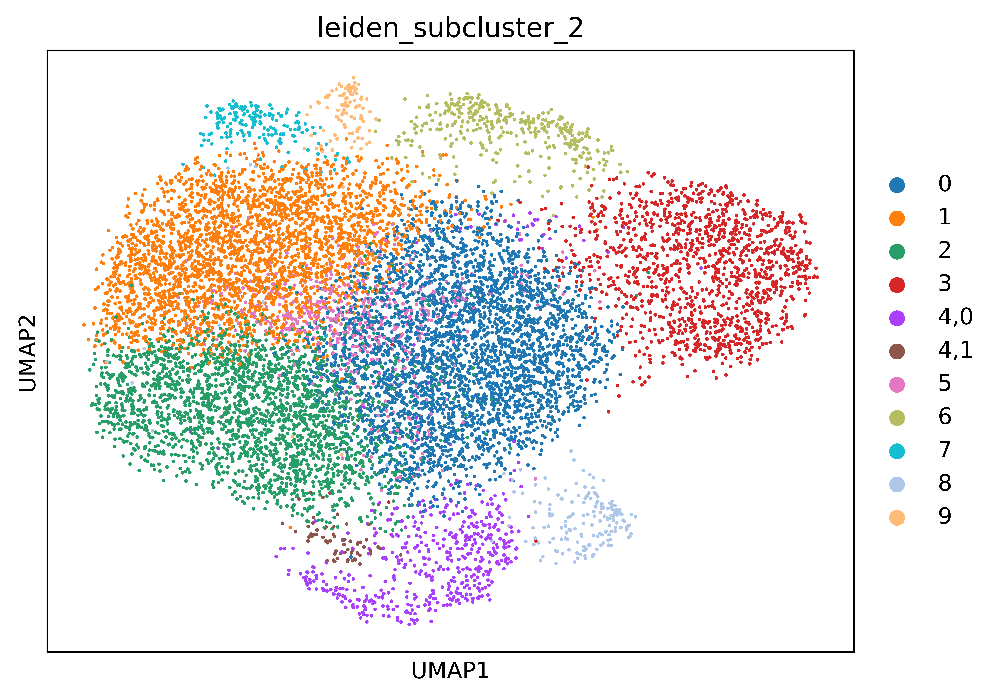

In [35]:
sc.pl.umap(adata_treg, color=["leiden_subcluster_2"], ncols= 1, save = "clustering_subclus_2", show=True)

In [36]:
# sc.pl.umap(Treg, color=["FOXP3", "TNFRSF18", "TNFRSF4", "BATF", "IL2RA", "TIGIT", "CTLA4", "PHLDA1", "TCF7", "IL7R", "SELL", "LEF1"], ncols=3, color_map=mpl.cm.Reds, save = "gene", show=False) 

In [37]:
# sc.pl.umap(Treg, color=["CD8A", "CCL5", "GZMA", "GZMK", "LAG3", "CXCL13", "IFNG", "TOX"], ncols=3, color_map=mpl.cm.Reds, save = "gene_2", show=False) 

# Dotplot and Heatmap

### leiden at resolution 0.50

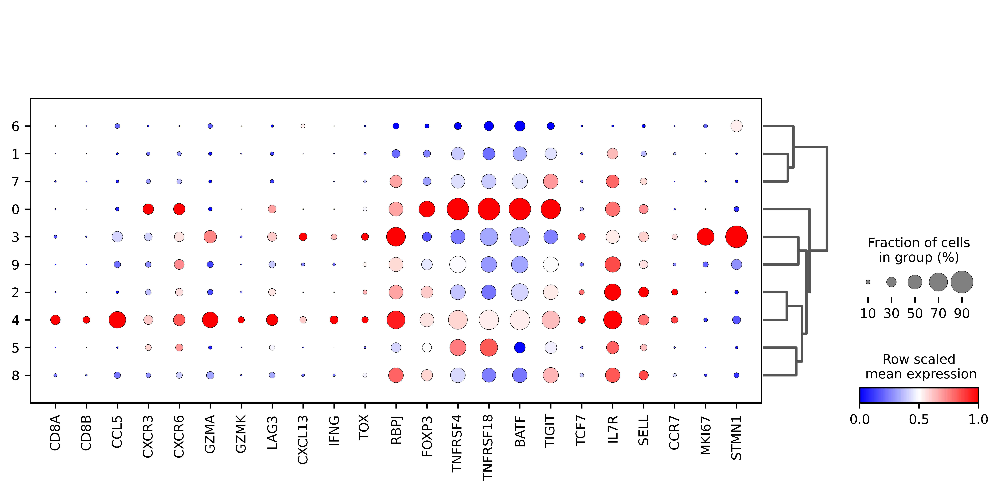

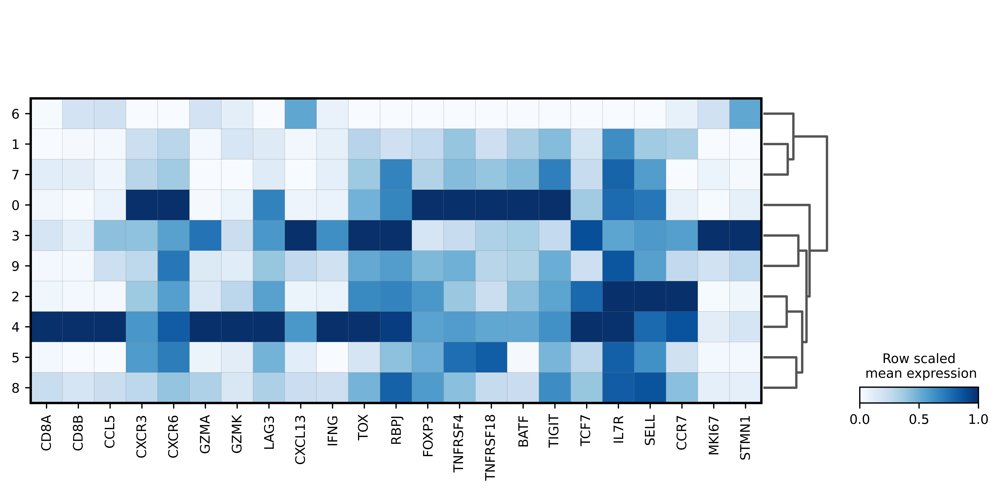

In [38]:
import scanpy as sc

genes = ["CD8A", "CD8B", "CCL5", "CXCR3", "CXCR6", "GZMA", "GZMK", "LAG3", "CXCL13", 
         "IFNG", "TOX", "RBPJ", "FOXP3", "TNFRSF4", "TNFRSF18", "BATF", "TIGIT", "TCF7", 
         "IL7R", "SELL", "CCR7", "MKI67", "STMN1"]

# Compute dendrogram
sc.tl.dendrogram(adata_treg, groupby='leiden_0.50')

# Show dotplot
sc.pl.dotplot(adata_treg, genes, groupby='leiden_0.50', swap_axes=False, dendrogram=True, 
              cmap='bwr', standard_scale='var', colorbar_title='Row scaled\n mean expression', show=True)

# Show matrixplot
sc.pl.matrixplot(adata_treg, genes, groupby='leiden_0.50', swap_axes=False, dendrogram=True, 
                 cmap='Blues', standard_scale='var', colorbar_title='Row scaled\n mean expression', show=True)


In [39]:
# genes_from_paper = ["FOXP3", "TNFRSF18", "TNFRSF4", "BATF", "IL2RA", "TIGIT", "CTLA4", "PHLDA1", "TCF7", "IL7R", "SELL", "LEF1", "CD8A", "CCL5", "GZMA", "GZMK", "LAG3", "CXCL13", "IFNG", "TOX", "RBPJ"]
# sc.pl.dotplot(Treg, genes_from_paper, groupby='leiden_0.50', swap_axes = False, dendrogram= True, cmap ='bwr', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'dotplot_0.5_genes_paper', show=False) 
# sc.pl.matrixplot(Treg, genes_from_paper, groupby='leiden_0.50', swap_axes = False, dendrogram= True, cmap ='Blues', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'matrixplot_0.5_genes_paper', show=False) 

In [40]:
# cxc_genes = ["CXCR3", "CXCR6", "CCR4", "CCR7", "CCR8"]
# sc.pl.dotplot(Treg, cxc_genes, groupby='leiden_0.50', swap_axes = False, dendrogram= True, cmap ='bwr', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'dotplot_0.5_cxc_genes_paper', show=False) 
# sc.pl.matrixplot(Treg, cxc_genes, groupby='leiden_0.50', swap_axes = False, dendrogram= True, cmap ='Blues', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'matrixplot_0.5_cxc_genes_paper', show=False) 

In [41]:
# genes = ["CD8A", "CD8B", "CCL5", "CXCR3", "CXCR6", "GZMA", "GZMK", "LAG3", "CXCL13", "IFNG", "TOX", "RBPJ", "FOXP3", "TNFRSF4", "TNFRSF18", "BATF", "TIGIT", "TCF7", "IL7R", "SELL", "CCR7", "MKI67", "STMN1"] 
# sc.tl.dendrogram(Treg, groupby='leiden_subcluster')
# sc.pl.dotplot(Treg, genes, groupby='leiden_subcluster', swap_axes = False, dendrogram= True, cmap ='bwr', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'dotplot_subclustering', show=False) 
# sc.pl.matrixplot(Treg, genes, groupby='leiden_subcluster', swap_axes = False, dendrogram= True, cmap ='Blues', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'matrixplot_subclustering', show=False) 

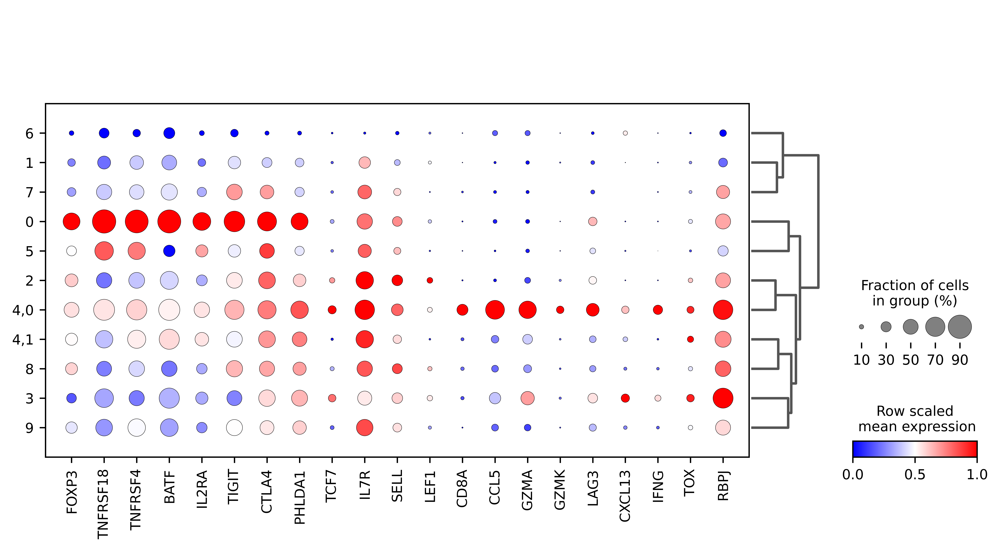

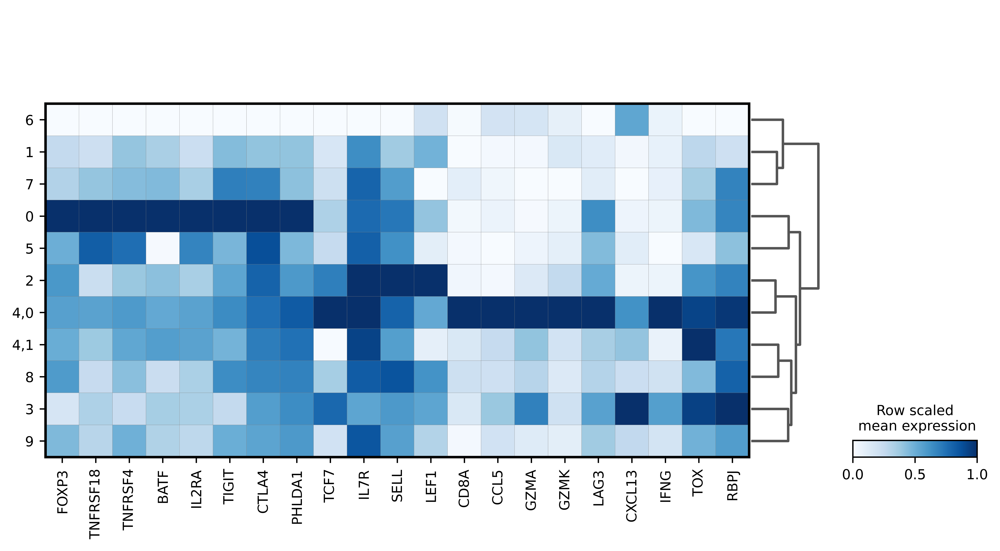

In [42]:
import scanpy as sc

genes_from_paper = ["FOXP3", "TNFRSF18", "TNFRSF4", "BATF", "IL2RA", "TIGIT", "CTLA4", "PHLDA1", 
                    "TCF7", "IL7R", "SELL", "LEF1", "CD8A", "CCL5", "GZMA", "GZMK", "LAG3", 
                    "CXCL13", "IFNG", "TOX", "RBPJ"]

# Compute dendrogram
sc.tl.dendrogram(adata_treg, groupby='leiden_subcluster')

# Save and show dotplot
sc.pl.dotplot(adata_treg, genes_from_paper, groupby='leiden_subcluster_2', swap_axes=False, dendrogram=True, 
              cmap='bwr', standard_scale='var', colorbar_title='Row scaled\n mean expression', 
              save='dotplot_subclustering_2_genes', show=True)

# Save and show matrixplot
sc.pl.matrixplot(adata_treg, genes_from_paper, groupby='leiden_subcluster_2', swap_axes=False, dendrogram=True, 
                 cmap='Blues', standard_scale='var', colorbar_title='Row scaled\n mean expression', 
                 save='matrixplot_subclustering_2_genes', show=True)


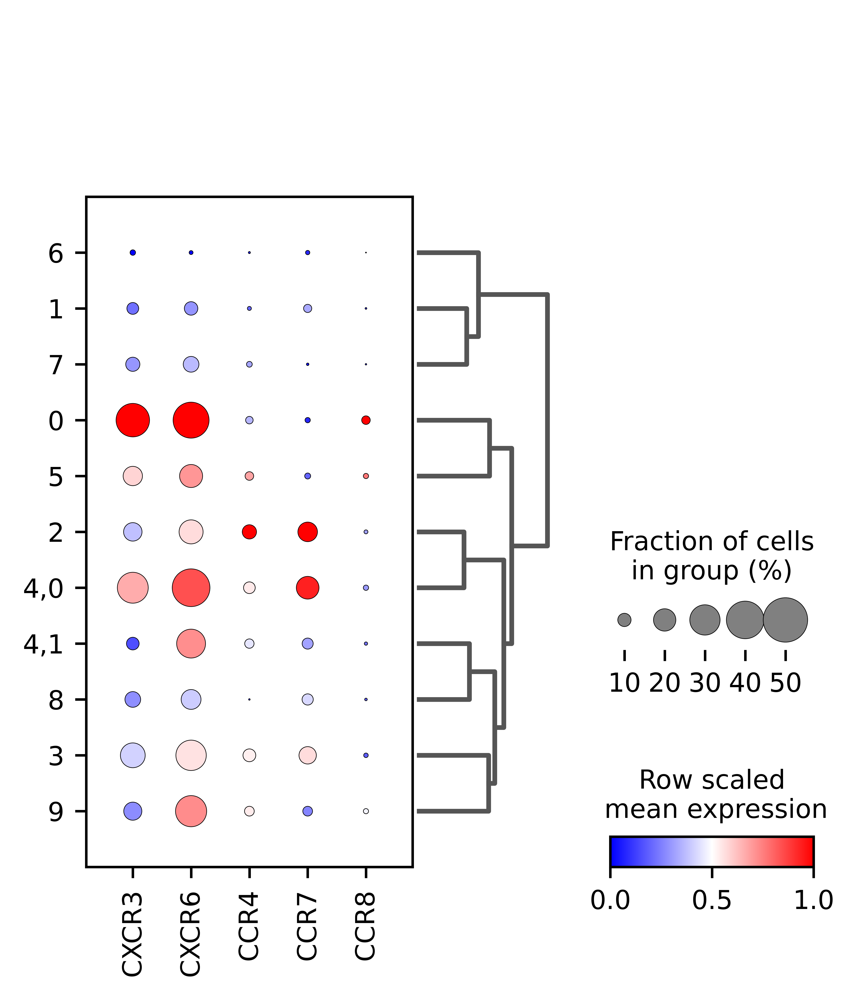

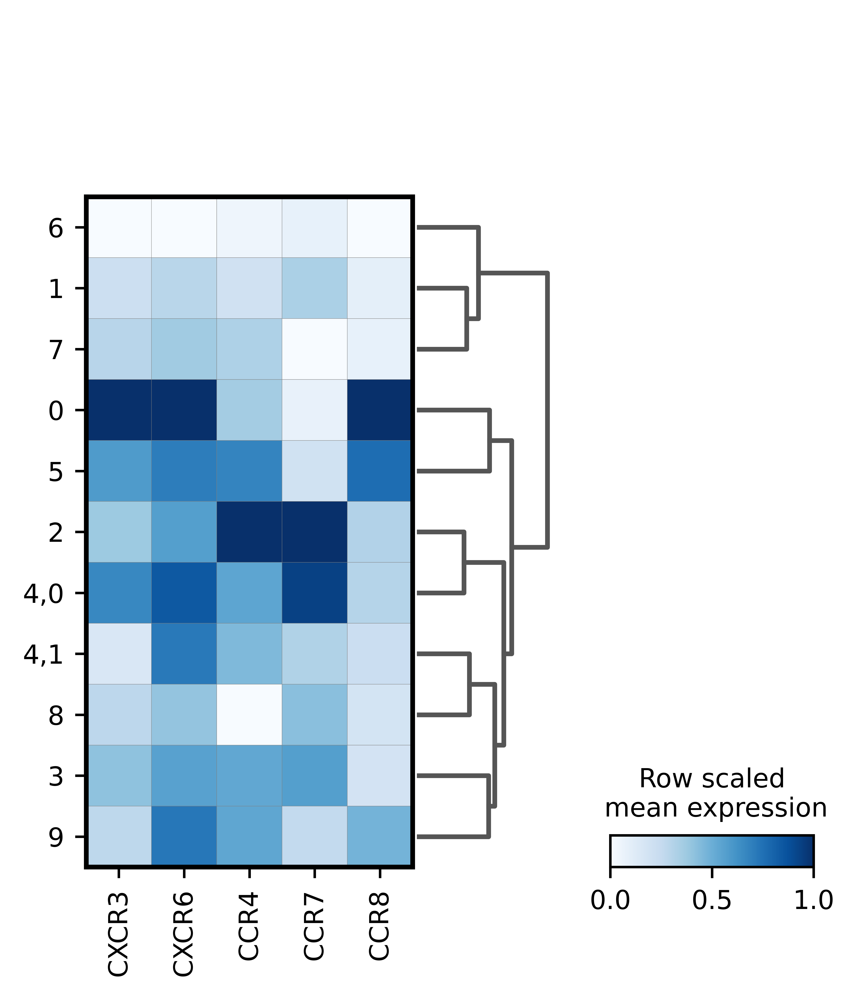

In [43]:
cxc_genes = ["CXCR3", "CXCR6", "CCR4", "CCR7", "CCR8"]
sc.pl.dotplot(adata_treg, cxc_genes, groupby='leiden_subcluster_2', swap_axes = False, dendrogram= True, cmap ='bwr', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'dotplot_subclustering_2_cxcrs', show=True) 
sc.pl.matrixplot(adata_treg, cxc_genes, groupby='leiden_subcluster_2', swap_axes = False, dendrogram= True, cmap ='Blues', standard_scale = 'var', colorbar_title = 'Row scaled\n mean expression', save = 'matrixplot_subclustering_2_cxcrs', show=True) 

In [44]:
cell_counts = adata_treg.obs['leiden_subcluster_2'].value_counts().to_dict()
print(cell_counts)


{'0': 3335, '1': 2804, '2': 2364, '3': 1302, '5': 553, '4,0': 510, '6': 357, '7': 184, '8': 176, '9': 106, '4,1': 64}


In [45]:
clus_0 = adata_treg[adata_treg.obs['leiden_subcluster_2'] == "0"]
clus_2 = adata_treg[adata_treg.obs['leiden_subcluster_2'] == "2"]
clus_4 = adata_treg[adata_treg.obs['leiden_subcluster_2'] == "4,0"]
foxp3cd8

def merge_and_add_clone_exp(adata1, adata2):
    merged_adata = ad.concat([adata1, adata2], join='outer', label='group', fill_value=0)
    merged_adata.obs['group'] = ['A'] * adata1.n_obs + ['B'] * adata2.n_obs
    return merged_adata

merged_pt_data = merge_and_add_clone_exp(clus_4, foxp3cd8)

def deg_res(adata):
    # Ensure non-zero variance calculation works for both sparse and dense matrices
    X = adata.X
    if isinstance(X, np.ndarray):  
        nonz_variance = (X > 0).sum(axis=0)  
    else:  # If sparse
        nonz_variance = (X > 0).sum(axis=0).A1  

    adata.var['nonz_variance'] = nonz_variance
    adata = adata[:, adata.var['nonz_variance'] > 0]
    
    # Perform differential expression analysis
    sc.tl.rank_genes_groups(adata, 'group', method='t-test')
    
    return sc.get.rank_genes_groups_df(adata, group='B')

# Run the function
mydf_res = deg_res(merged_pt_data)



/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/merge.py:1362: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(
/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1818: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1818: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
/home/jupyter/.local/lib/python3.10/site-packages/anndata/_core/anndata.py:1209: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  

In [48]:
import matplotlib.pyplot as plt
import numpy as np

def vol_plot(df_something, labeled_genes, p_value_cutoff=0.05, fold_change_cutoff=0, log_pval_cutoff=0, save_path=None):
    significant_genes = (df_something['pvals_adj'] < p_value_cutoff) & (np.abs(df_something['logfoldchanges']) > np.log2(fold_change_cutoff))
    labeled_genes_mask = df_something['names'].isin(labeled_genes)
    df_something['log_pval'] = df_something['pvals_adj'].apply(lambda x: min(-np.log10(x), 250))
    high_log_pval_mask = df_something['log_pval'] > log_pval_cutoff
    extra_labeled_genes_mask = (~labeled_genes_mask) & (np.abs(df_something['logfoldchanges']) > 1) & (df_something['log_pval'] >= 15)
    final_labeled_genes_mask = labeled_genes_mask | extra_labeled_genes_mask
    plt.figure(figsize=(16, 16))
    plt.scatter(x=df_something[~significant_genes]['logfoldchanges'], y=df_something[~significant_genes]['log_pval'], s=10, label="Not significant", c='gray')
    plt.scatter(x=df_something[significant_genes]['logfoldchanges'], y=df_something[significant_genes]['log_pval'], s=25, label="Significant", c='blue')
    plt.scatter(x=df_something[final_labeled_genes_mask]['logfoldchanges'], y=df_something[final_labeled_genes_mask]['log_pval'], s=50, label="Labeled genes", c='red')
    for gene, x, y in zip(df_something[final_labeled_genes_mask]['names'], df_something[final_labeled_genes_mask]['logfoldchanges'], df_something[final_labeled_genes_mask]['log_pval']):
        color = 'green' if gene in labeled_genes else 'purple'
        ha = 'left' if x > 0 else 'right'
        plt.annotate(gene, (x + (0.05 if x > 0 else -0.05), y), fontsize=15, ha=ha, va='center', color=color)
    plt.xticks(fontsize=30)
    plt.yticks(fontsize=30)
    plt.grid(False)
    if save_path:
        plt.savefig(save_path, format='pdf', dpi=300, bbox_inches='tight')
        plt.show()
    plt.close()


In [46]:
def vol_plot(df_something, labeled_genes, p_value_cutoff=0.05, fold_change_cutoff=0, log_pval_cutoff=0, save_path=None):
    significant_genes = (df_something['pvals_adj'] < p_value_cutoff) & (np.abs(df_something['logfoldchanges']) > np.log2(fold_change_cutoff))
    labeled_genes_mask = df_something['names'].isin(labeled_genes)
    df_something['log_pval'] = df_something['pvals_adj'].apply(lambda x: min(-np.log10(x), 250))
    high_log_pval_mask = df_something['log_pval'] > log_pval_cutoff
    extra_labeled_genes_mask = (~labeled_genes_mask) & (np.abs(df_something['logfoldchanges']) > 1) & (df_something['log_pval'] >= 15)
    final_labeled_genes_mask = labeled_genes_mask | extra_labeled_genes_mask
    plt.figure(figsize=(16, 16))
    plt.scatter(x=df_something[~significant_genes]['logfoldchanges'], 
                y=df_something[~significant_genes]['log_pval'], 
                s=10, label="Not significant", c='gray')
    plt.scatter(x=df_something[significant_genes]['logfoldchanges'], 
                y=df_something[significant_genes]['log_pval'], 
                s=25, label="Significant", c='blue')
    plt.scatter(x=df_something[final_labeled_genes_mask]['logfoldchanges'], 
                y=df_something[final_labeled_genes_mask]['log_pval'], 
                s=50, label="Labeled genes", c='red')
    
    # Only label genes that are in the labeled_genes list
    for gene, x, y in zip(df_something[final_labeled_genes_mask & labeled_genes_mask]['names'], 
                          df_something[final_labeled_genes_mask & labeled_genes_mask]['logfoldchanges'], 
                          df_something[final_labeled_genes_mask & labeled_genes_mask]['log_pval']):
        color = 'green'  # Set the color for labeled genes
        ha = 'left' if x > 0 else 'right'
        plt.annotate(gene, (x + (0.05 if x > 0 else -0.05), y), fontsize=25, ha=ha, va='center', color=color)
    
    plt.xticks(fontsize=30)
    plt.yticks(fontsize=30)
    plt.grid(False)
    if save_path:
        plt.savefig(save_path, format='pdf', dpi=300, bbox_inches='tight')
        plt.show()

    plt.close()


In [49]:
df_res_sub_10 = mydf_res[abs(mydf_res['logfoldchanges']) < 10]
df_res_gte_10 = mydf_res[abs(mydf_res['logfoldchanges']) >= 10]

# sc.set_figure_params(facecolor="white", figsize=(16, 16))

labeled = ['TCF7','CCR7','FOXP3','IL2RA','BATF','TNFRSF18','TNFRSF4','CTLA4','CCL5','CD8A','CXCL13','GZMB','CD8B','IFNG','']
# labeled = ['FOXP3','IL2RA','IL32','S100A4','LTB','CCR8','TNFRSF4','TIGIT','BATF','TNFRSF18','CTLA4',
#            'CCL5','GZMA','NKG7','CCL4','CD8A','CD8B','GZMH','GZMB','IFNG','CXCL13','IFITM1','CD69','ZNF683','TCF7','TBX21']



vol_plot(df_res_sub_10, labeled, save_path = 'pilot')
print(df_res_sub_10)


# labeled = ['MARCO','S100A10','INHBA','CSTB','SPP1','S100A4',
#           'GBP1','HLA-DPB1','HLA-DPA1','CXCL10','CXCL9','CXCL11',
#           'CCL3','CCL4','FCN1']

/tmp/ipykernel_7843/410366797.py:5: RuntimeWarning: divide by zero encountered in log2
  significant_genes = (df_something['pvals_adj'] < p_value_cutoff) & (np.abs(df_something['logfoldchanges']) > np.log2(fold_change_cutoff))
/tmp/ipykernel_7843/410366797.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_something['log_pval'] = df_something['pvals_adj'].apply(lambda x: min(-np.log10(x), 250))


            names     scores  logfoldchanges          pvals      pvals_adj  \
179          JUNB  53.961571        7.625260  2.854137e-310  3.417734e-308   
243        IFITM1  41.719692        7.494121  1.134148e-240  1.039366e-238   
270           LTB  39.052528        8.485302  3.741307e-207  2.847515e-205   
291          HCST  37.954769        5.035233  5.914101e-211  4.618656e-209   
325       ZFP36L1  35.986412        4.679589  1.872299e-195  1.334533e-193   
...           ...        ...             ...            ...            ...   
17931     ANKRD28 -10.435617       -3.028306   1.638952e-23   8.483820e-23   
17932       MS4A1 -10.503308       -6.817561   1.654471e-23   8.561684e-23   
17935        IGKC -10.796753       -3.712887   6.233821e-25   3.388980e-24   
17939       KLRD1 -12.233642       -3.747163   1.015905e-30   6.760908e-30   
17950  AC092580.4 -16.636612       -7.428176   4.466330e-50   5.205984e-49   

         log_pval  
179    250.000000  
243    237.983231  
270

/tmp/ipykernel_6125/3794949332.py:34: RuntimeWarning: invalid value encountered in log2
  logFC = np.log2((mean1 + 1e-5) / (mean2 + 1e-5))  # Adding small value to avoid division by zero
/home/jupyter/.local/lib/python3.10/site-packages/scipy/stats/_axis_nan_policy.py:573: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/tmp/ipykernel_6125/3794949332.py:40: RuntimeWarning: divide by zero encountered in log10
  log_pvals = -np.log10(pvals)


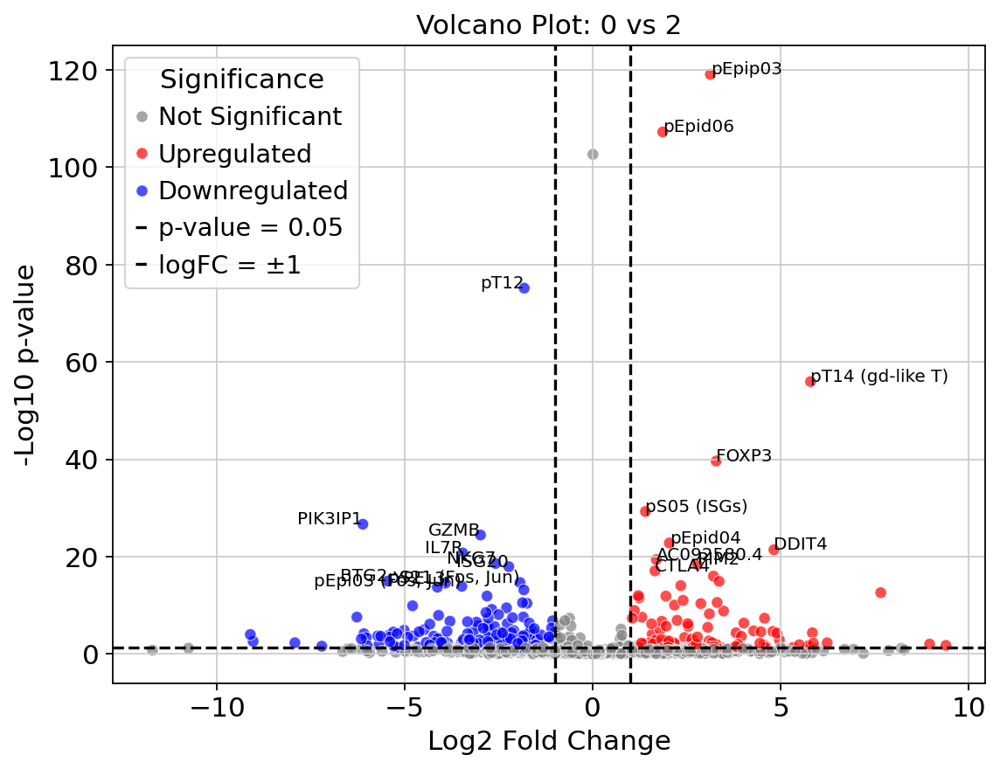

In [123]:
import scanpy as sc
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
import numpy as np

def volcano_plot(adata, cluster1, cluster2, logfc_threshold=1, pval_threshold=0.05, top_n=10):
    """
    Generate a volcano plot comparing gene expression between two leiden_subcluster_2 groups.
    
    Parameters:
    adata (AnnData): AnnData object containing gene expression data.
    cluster1 (str): Value of leiden_subcluster_2 for the first group.
    cluster2 (str): Value of leiden_subcluster_2 for the second group.
    logfc_threshold (float): Threshold for log fold change highlighting.
    pval_threshold (float): Threshold for p-value significance highlighting.
    top_n (int): Number of top upregulated and downregulated genes to label.
    """
    
    # Subset the data
    group1 = adata[adata.obs['leiden_subcluster_2'] == cluster1]
    group2 = adata[adata.obs['leiden_subcluster_2'] == cluster2]

    # Get expression values
    X1 = group1.X.toarray() if hasattr(group1.X, "toarray") else group1.X
    X2 = group2.X.toarray() if hasattr(group2.X, "toarray") else group2.X

    # Compute mean expression
    mean1 = np.mean(X1, axis=0)
    mean2 = np.mean(X2, axis=0)

    # Compute log fold change
    logFC = np.log2((mean1 + 1e-5) / (mean2 + 1e-5))  # Adding small value to avoid division by zero

    # Compute p-values using t-test
    pvals = np.array([ttest_ind(X1[:, i], X2[:, i], equal_var=False).pvalue for i in range(X1.shape[1])])

    # Adjust p-values using -log10 transformation
    log_pvals = -np.log10(pvals)

    # Create a DataFrame for plotting
    volcano_df = pd.DataFrame({
        'gene': adata.var.index,
        'logFC': logFC,
        'pval': pvals,
        '-log10(pval)': log_pvals
    })

    # Define significance criteria
    volcano_df['significance'] = 'Not Significant'
    volcano_df.loc[(volcano_df['logFC'] > logfc_threshold) & (volcano_df['pval'] < pval_threshold), 'significance'] = 'Upregulated'
    volcano_df.loc[(volcano_df['logFC'] < -logfc_threshold) & (volcano_df['pval'] < pval_threshold), 'significance'] = 'Downregulated'

    # Select top genes for labeling
    top_up = volcano_df[volcano_df['significance'] == 'Upregulated'].nlargest(top_n, '-log10(pval)')
    top_down = volcano_df[volcano_df['significance'] == 'Downregulated'].nlargest(top_n, '-log10(pval)')

    # Plot
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=volcano_df, x='logFC', y='-log10(pval)', hue='significance', 
                    palette={'Upregulated': 'red', 'Downregulated': 'blue', 'Not Significant': 'gray'}, alpha=0.7)
    
    # Add horizontal and vertical threshold lines
    plt.axhline(-np.log10(pval_threshold), linestyle='dashed', color='black', label=f'p-value = {pval_threshold}')
    plt.axvline(logfc_threshold, linestyle='dashed', color='black', label=f'logFC = ±{logfc_threshold}')
    plt.axvline(-logfc_threshold, linestyle='dashed', color='black')

    # Annotate top genes
    for _, row in pd.concat([top_up, top_down]).iterrows():
        plt.text(row['logFC'], row['-log10(pval)'], row['gene'], fontsize=9, ha='right' if row['logFC'] < 0 else 'left')

    plt.xlabel('Log2 Fold Change')
    plt.ylabel('-Log10 p-value')
    plt.title(f'Volcano Plot: {cluster1} vs {cluster2}')
    plt.legend(title='Significance')
    plt.show()

# Example usage:
volcano_plot(adata_treg, "0", "2")
